# Lesson 4 — Training: how the model learns

⏱ **Duration:** ~30 min &nbsp;|&nbsp; 📚 **Builds on:** Lesson 3 &nbsp;|&nbsp; 💻 **Runs on:** a laptop CPU

**By the end of this lesson you will be able to:**

- write the four steps of a training iteration (forward, loss, backward, update)
- interpret cross-entropy loss and perplexity
- explain learning-rate warm-up + cosine decay and the wall-clock budget
- read the training charts and recorded times

> 🎤 *Teaching tip:* run the cells in order; every code cell is short enough to be explained live.

## 1. The idea

Start with random weights → the model is clueless: at each position it assigns about the same probability to every word.
Training repeats four steps thousands of times:

1. **Forward** — run a batch `x` through the model, get predictions
2. **Loss** — compare with the true next tokens `y` (cross-entropy)
3. **Backward** — compute how each weight should change to reduce the loss (gradients)
4. **Update** — move every weight a small step (the *learning rate*) in that direction

**Cross-entropy** = `−log(probability the model gave to the correct next word)`. Perfect → 0. Uniform guess over a
vocabulary of V words → `log V`. **Perplexity** = `exp(loss)`: "the model is as uncertain as if choosing among *perplexity* equally likely words".

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # lets us `import myllm` without installing it

import torch
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(4)
DATA = ROOT / "data" / "raw"       # training text lives here
MODELS = ROOT / "models"           # checkpoints are written here

In [2]:
import math
from myllm.data import load_corpus, split_ids, get_batch
from myllm.tokenizer import WordTokenizer
from myllm.model import GPT, GPTConfig

corpus = load_corpus(DATA)
tok = WordTokenizer.train(corpus, 2000)
train_ids, val_ids = split_ids(tok.encode(corpus))
print(f"{len(train_ids):,} training tokens, vocab {tok.vocab_size}")
print(f"loss of a clueless model  = log(vocab) = {math.log(tok.vocab_size):.2f}  (perplexity {tok.vocab_size})")

1,136,670 training tokens, vocab 2000
loss of a clueless model  = log(vocab) = 7.60  (perplexity 2000)


## 2. A training loop by hand (60 steps)

loss: 7.61 -> 5.40


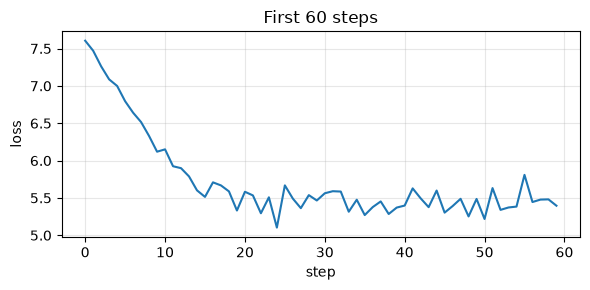

In [3]:
torch.manual_seed(0)
gen = torch.Generator().manual_seed(0)
model = GPT(GPTConfig(vocab_size=tok.vocab_size, n_layer=2, n_head=2, n_embd=64, block_size=32))
opt = torch.optim.AdamW(model.parameters(), lr=3e-3)

losses = []
for step in range(60):
    x, y = get_batch(train_ids, batch_size=16, block_size=32, generator=gen)   # a batch
    logits, loss = model(x, y)                                                 # 1+2. forward + loss
    opt.zero_grad()
    loss.backward()                                                            # 3. gradients
    opt.step()                                                                 # 4. update
    losses.append(loss.item())

print(f"loss: {losses[0]:.2f} -> {losses[-1]:.2f}")
plt.figure(figsize=(6, 3)); plt.plot(losses); plt.xlabel("step"); plt.ylabel("loss"); plt.title("First 60 steps")
plt.tight_layout()

The loss drops quickly at first: the model learns that frequent words (`the`, `and`, `,`) are likely everywhere.
Later progress is slower — it must learn grammar and context.

## 3. The learning rate schedule

Too large a learning rate → unstable. Too small → slow. We use:

* **warm-up** (first 100 steps): increase from ~0 to the peak so early, noisy gradients do no damage
* **cosine decay**: smoothly shrink to 10 % of the peak so the model settles into a good minimum

In `myllm` the schedule follows **elapsed time ÷ time budget**, so any budget (1 or 10 minutes) ends exactly at the minimum LR.

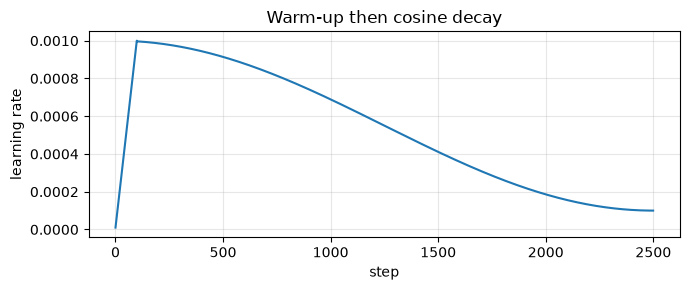

In [4]:
from myllm.train import TrainConfig, lr_at
cfg = TrainConfig(lr=1e-3, warmup_steps=100)
steps = range(0, 2500)
plt.figure(figsize=(7, 3))
plt.plot(steps, [lr_at(s / 2500, s, cfg) for s in steps])
plt.xlabel("step"); plt.ylabel("learning rate"); plt.title("Warm-up then cosine decay")
plt.tight_layout()

## 4. The real thing: `train()` with a time budget

`myllm.train.train` wraps the loop above and adds: validation every 200 steps, gradient clipping, the schedule,
saving the **best** checkpoint, and a JSON log with all the times.

We train the `tiny` preset for **1 minute** (the `default` preset takes 10 — see lesson 8).

In [5]:
from myllm.train import train
MODELS.mkdir(exist_ok=True)
result = train(DATA, MODELS / "lesson_tiny.pt", TrainConfig(preset="tiny", minutes=1.0, eval_every=100))

corpus: 1,196,318 tokens, vocab 2,000
model: 230,144 parameters, budget 1.0 min on cpu
step     0 |    0.0s | train nan | val 7.601 | ppl 1999.6
step   100 |    3.1s | train 5.557 | val 5.408 | ppl 223.2
step   200 |    5.9s | train 4.882 | val 4.734 | ppl 113.8
step   300 |    8.8s | train 4.596 | val 4.493 | ppl 89.4
step   400 |   11.8s | train 4.388 | val 4.278 | ppl 72.1
step   500 |   14.9s | train 4.274 | val 4.272 | ppl 71.6
step   600 |   17.9s | train 4.242 | val 4.208 | ppl 67.2
step   700 |   20.7s | train 4.270 | val 4.132 | ppl 62.3
step   800 |   23.7s | train 4.170 | val 4.137 | ppl 62.6
step   900 |   26.4s | train 4.195 | val 4.041 | ppl 56.9
step  1000 |   29.4s | train 4.157 | val 4.062 | ppl 58.1
step  1100 |   32.2s | train 4.098 | val 4.087 | ppl 59.6
step  1200 |   35.0s | train 4.079 | val 3.971 | ppl 53.0
step  1300 |   37.9s | train 4.101 | val 3.912 | ppl 50.0
step  1400 |   40.8s | train 3.978 | val 3.869 | ppl 47.9
step  1500 |   43.7s | train 4.071 | val 

## 5. Reading the results

In [6]:
print(f"steps            : {result.steps:,}")
print(f"parameters       : {result.n_params:,}")
print(f"best val loss    : {result.val_loss:.3f}   (perplexity {math.exp(result.val_loss):.1f})")
print("recorded timings :")
for k, v in result.timings.items():
    print(f"   {k:15s} {v:10.1f}")

steps            : 2,024
parameters       : 230,144
best val loss    : 3.858   (perplexity 47.4)
recorded timings :
   load_corpus_s          0.6
   tokenize_s             1.1
   train_s               60.2
   tokens_per_s       17203.2


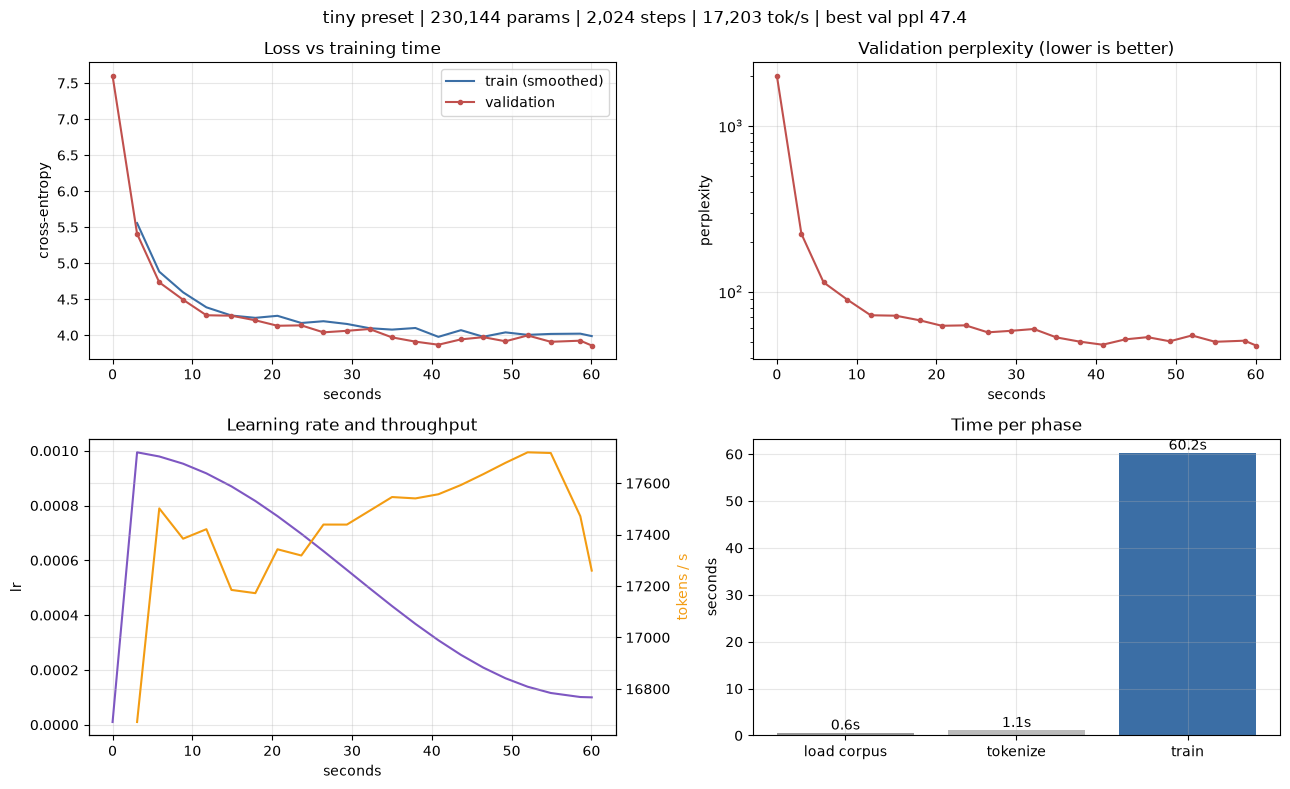

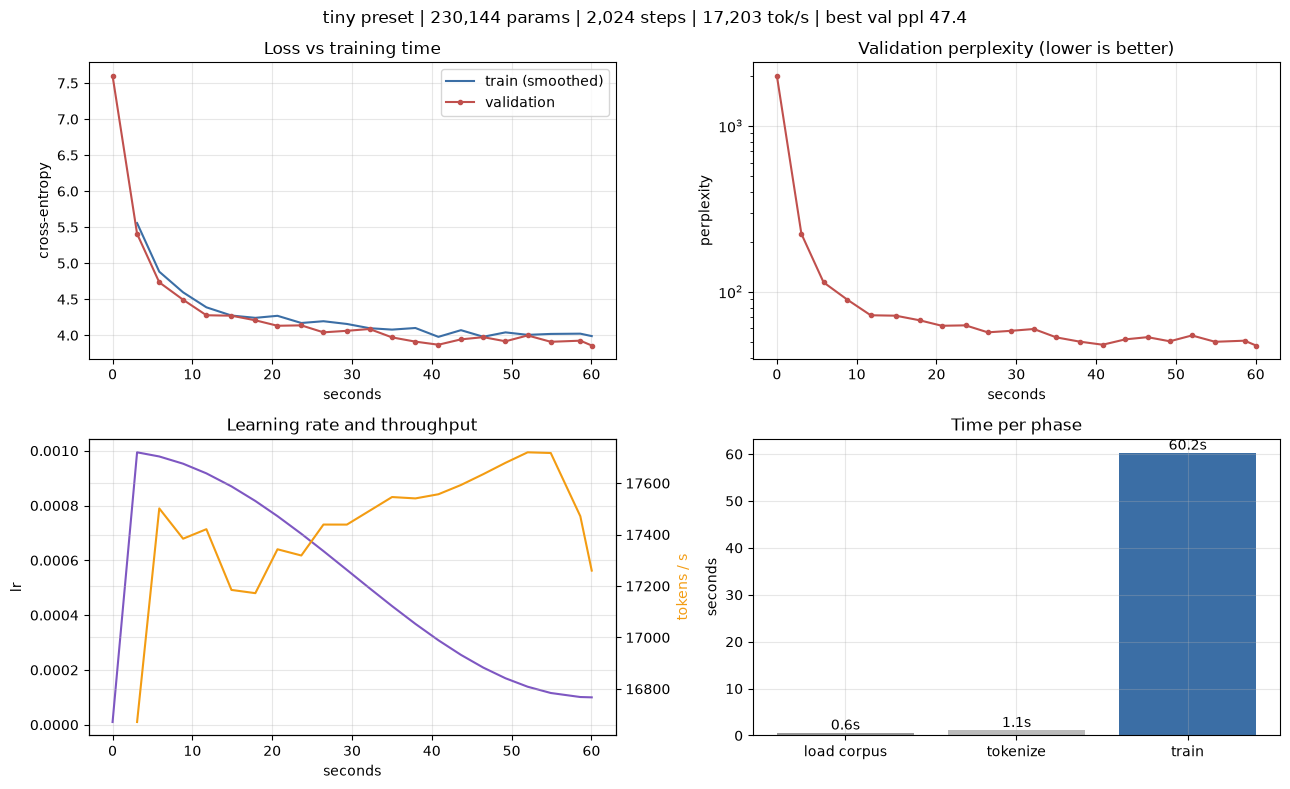

In [7]:
from myllm.plots import training_figure
from myllm.train import history_path_for
training_figure(history_path_for(MODELS / "lesson_tiny.pt"))

How to read the four charts:

* **top-left** — loss over time. Train and validation should go down *together*. If train keeps falling while validation rises → **overfitting**.
* **top-right** — the same as perplexity (log scale). It starts at the vocabulary size (2000) and falls to roughly 50.
* **bottom-left** — learning rate (purple) and throughput in tokens/s (orange).
* **bottom-right** — where the time went: loading and tokenizing are negligible; training dominates.

---
## ✅ Key takeaways

- Training = forward, loss, backward, update, repeated; loss is `−log p(correct next word)`.
- Perplexity = `exp(loss)`; an untrained model has perplexity ≈ vocabulary size.
- Warm-up + cosine decay (driven by the time budget) gives a stable, predictable run.
- Always compare train and validation loss to spot overfitting.

## 🧪 Exercises

1. Re-run the hand-written loop with `lr=1e-4` and `lr=3e-2`. Plot all three losses together.
2. Train the tiny preset for 2 minutes instead of 1. How much better is the validation perplexity? Is it worth double the time?
3. In `train.py` find where gradients are clipped. What happens to the loss if you set `grad_clip=100`?

## ➡️ Next

**Lesson 5 — Inference:** using the trained model to write text.